In [1]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer
import re
import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import TweetTokenizer
import string
import matplotlib.pyplot as plt
from collections import Counter
from textblob import TextBlob, Word, Blobber
from textblob.classifiers import NaiveBayesClassifier
from textblob.taggers import NLTKTagger

In [12]:
#df for Texblob
with open('central_tweets/community_0_1Kmostcentral_2025-05-03.txt', 'r', encoding='utf-8') as file:
    tweets_list = [line.strip() for line in file if line.strip()]
print(len(tweets_list))

60122


In [3]:
tweets_list[1:5]

['They only care about maintaining their own agenda.',
 'Truly sad that even now they refuse to unite@funder I doubt @senatemajldr is immune to the coronavirus, and both trump and pence have been exposed to the virus… https://t.co/UB5IaPvs4r@funder @realDonaldTrump Trump knew about the Coronavirus in December. Pass it on.WTF! @senatemajldr must go! This man is crazier than @realDonaldTrumpMcConnell and trump are like two rotten mildewy peas in a pod!  Both are rotten to the core...#MoscowMitch Is willing to allow Americans to die because he supports Putin in Russia. A week America equals a stronger Russia equals a wealthier Mitch McConnell@funder @realDonaldTrump #COVIDー19 #coronavirus #Covid19US #TrumpVirus #TrumpVirusCoverup',
 '@realDonaldTrump @VP',
 '@CDCgov @HHSGov']

In [4]:
english_stopwords = stopwords.words("english")

punctuation_words = string.punctuation

In [5]:
tweets_list[3]

'@realDonaldTrump @VP'

In [6]:
clean_tweets = []

for tweet in tweets_list:
    
    tweet = str(tweet) 

    tweet = re.sub(r'^RT[\s]+', '', tweet)
    tweet = re.sub(r'\$\w*', '', tweet)
    tweet = re.sub(r'$', '', tweet)
    tweet = re.sub(r'https?://[^\s\n\r]+', '', tweet)
    tweet = re.sub(r'https?://[A-Za-z0-9./]+','',tweet)
    tweet = re.sub(r'https//[A-Za-z0-9./]+','',tweet)
    tweet = tweet.replace("\n","")
    tweet = re.sub('@[\w]+', '', tweet)

    tweet = re.sub(r"n't", " not ", tweet)
    tweet = re.sub(r"\'s", " ", tweet)
    tweet = re.sub(r"\'ve", " have ", tweet)
    tweet = re.sub(r"\'re", " are ", tweet)
    tweet = re.sub(r"\'d", " would ", tweet)
    tweet = re.sub(r"\'ll", " will ", tweet) 

    tweet = tweet.lower()
    tweet = tweet.strip()
    
    if len(tweet) > 0:
        clean_tweets.append(tweet)

In [7]:
print(clean_tweets[:5])
print("-"*20)
print(tweets_list[:5])

['confirming what we already know...   and the rest of the  do not  give a damn about the american public or the #coronavirus #coronaviruspandemic', 'they only care about maintaining their own agenda.', 'truly sad that even now they refuse to unite i doubt  is immune to the coronavirus, and both trump and pence have been exposed to the virus…   trump knew about the coronavirus in december. pass it on.wtf!  must go! this man is crazier than  and trump are like two rotten mildewy peas in a pod!  both are rotten to the core...#moscowmitch is willing to allow americans to die because he supports putin in russia. a week america equals a stronger russia equals a wealthier mitch mcconnell  #covidー19 #coronavirus #covid19us #trumpvirus #trumpviruscoverup', 'wtf is going on?', '#topplethegop2020']
--------------------
["@funder Confirming what we already know... @senatemajldr @realDonaldTrump and the rest of the @GOP don't give a damn about the American public or the #Coronavirus #CoronavirusPa

In [11]:
df = pd.DataFrame(clean_tweets)
print(len(clean_tweets))
print(len(tweets_list))

57909
60122


In [13]:
for row in df.itertuples():
    tweet = df.at[row[0],0]
    analysis = TextBlob(tweet)
    df.at[row[0], 'polarity'] = analysis.sentiment[0]
    df.at[row[0], 'subjectivity'] = analysis.sentiment[1]
    if analysis.sentiment[0]>0:
        df.at[row[0], 'Sentiment'] = "Positive"
    elif analysis.sentiment[0]<0:
        df.at[row[0], 'Sentiment'] = "Negative"
    else:
        df.at[row[0], 'Sentiment'] = "Neutral"
    df.to_csv('textblob_comunity_00.csv', index=False)

In [14]:
df.head()

,0,polarity,subjectivity,Sentiment
0,confirming what we already know... and the r...,0.000000,0.033333,Neutral
1,they only care about maintaining their own age...,0.300000,1.000000,Positive
2,truly sad that even now they refuse to unite i...,-0.363281,0.875000,Negative
3,wtf is going on?,-0.500000,1.000000,Negative
4,#topplethegop2020,0.000000,0.000000,Neutral


KeyError: 'sentiment'

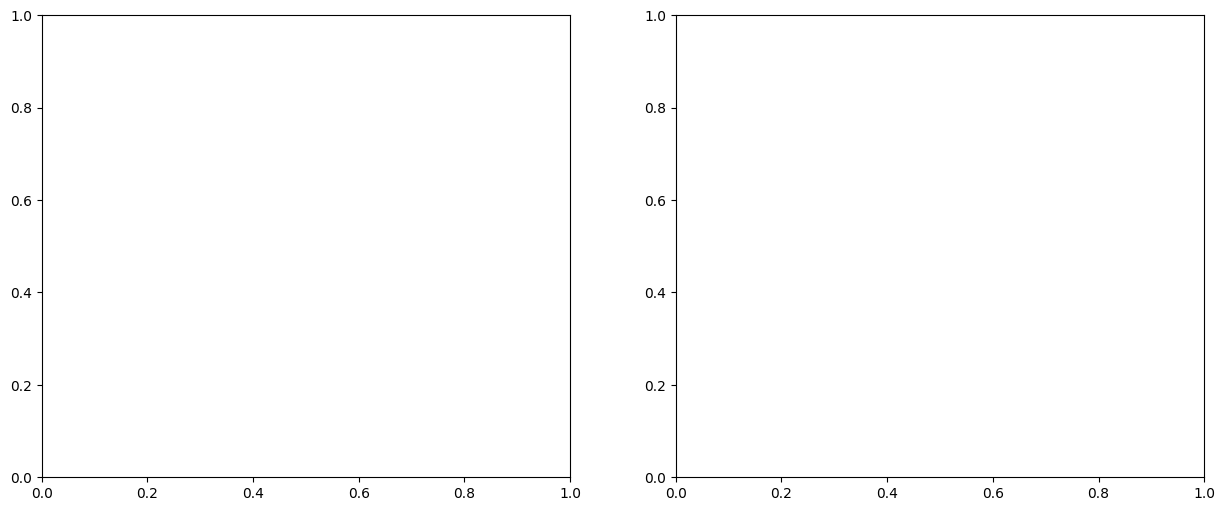

In [37]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# All tweets sentiment pie chart - using your existing sentiment column
sentiment_counts = df['sentiment'].value_counts()
ax1.pie(sentiment_counts, labels=sentiment_counts.index, autopct='%1.1f%%', startangle=90)
ax1.set_title('Sentiment Distribution (All Tweets)')

# Polarity score distribution histogram
ax2.hist(df['polarity'], bins=30, color='blue', alpha=0.5)
ax2.set_title('Distribution of TextBlob Polarity Scores')
ax2.set_xlabel('Polarity Score')
ax2.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

# Additional visualizations for both polarity and subjectivity
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# Polarity distribution with KDE
sns.histplot(data=df, x='polarity', kde=True, color='blue', alpha=0.5, ax=ax1)
ax1.set_title('Distribution of Polarity Scores')
ax1.set_xlabel('Polarity Score')
ax1.set_ylabel('Frequency')

# Subjectivity distribution with KDE
sns.histplot(data=df, x='subjectivity', kde=True, color='green', alpha=0.5, ax=ax2)
ax2.set_title('Distribution of Subjectivity Scores')
ax2.set_xlabel('Subjectivity Score')
ax2.set_ylabel('Frequency')

plt.tight_layout()
plt.show()

# Scatter plot showing relationship between polarity and subjectivity
plt.figure(figsize=(10, 8))
scatter = plt.scatter(df['polarity'], df['subjectivity'], 
                     c=df['sentiment'].astype('category').cat.codes, 
                     alpha=0.6, cmap='viridis')

# Add a colorbar legend
legend1 = plt.colorbar(scatter)
legend1.set_label('Sentiment Category')

plt.title('Relationship Between Polarity and Subjectivity')
plt.xlabel('Polarity')
plt.ylabel('Subjectivity')
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()